# Conangla et al. (2020): a hybrid Paul-optical trap

G. P. Conangla, R. A. Rica and R. Quidant, *Extending vacuum trapping to absorbing objects with hybrid
Paul-optical traps*, Nano Lett. **20**, 6018 (2020),
[doi:10.1021/acs.nanolett.0c02025](https://doi.org/10.1021/acs.nanolett.0c02025) (open version: arXiv:2005.05486).

A charged nanoparticle sits in an endcap Paul trap driven at $\omega_d/2\pi$ = 1-30 kHz, and a weak,
tightly focused laser (0.8 NA, ≤ 20 mW) adds an optical "dimple" at the Paul-trap centre. The paper
simulates the position density of a 100 nm dielectric particle at decreasing laser powers (Fig. 4) and
reports that the density deviates from a normal distribution below about 8 mW and that at 1 mW
the particle leaves and re-enters the focus; in the experiment (Fig. 5c, nanodiamonds, 532 nm) the
particle oscillates "in the range of hundreds of kHz" once the laser is at 10 mW or more, and at 1 mW
the spectrum is dominated by the drive at 20 kHz.

This notebook builds the hybrid trap from a `PaulTrap` and a `Tweezer` in one `Trap` and compares

1. the Paul trap's Mathieu parameters, secular frequencies and stability at the paper's parameters,
2. the optical trap frequency of a nanodiamond at 10 mW of 532 nm light with "hundreds of kHz",
3. the equilibrium position density (the paper's Eq. 2, adiabatic approximation) against Fig. 4,
4. stochastic time-domain simulations with the full rf force against that density, and their spectra
   against Fig. 5c,
5. the Paul-trap offset at which the optical dimple loses the particle (Fig. 2).

## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| drive frequency $\omega_d/2\pi$ | 20 kHz | Fig. 5c ("peak at $\omega_d$ = 20 kHz"); range 0.5-20 kHz in the simulation parameters (SM) |
| Paul-trap strength $\epsilon = QV/d^2$ | 2.16 × 10⁻⁸ N/m ($Q$ = 150 e, $V$ = 900 V, $d$ = 1 mm) | SM ranges: 50 ≤ $Q$/e ≤ 1000, 500 ≤ $V$ ≤ 2000 V, 0.1 < $d$ < 1 mm, $\epsilon$ ∈ [4 × 10⁻⁹, 3 × 10⁻⁵]; the values are **chosen** inside them (not stated) so that $q$ = 0.30 on the trap axis |
| trap geometry | endcap (ring) quadrupole, symmetry axis = levisim's $x$ | main text ("end-cap Paul trap ... with rotational symmetry"); Eq. 1 is the field along the trap axis, $m\ddot x = (QV/d^2)\cos(\omega_d t)\,x$, so $\kappa_\mathrm{geom}\,|a_x|/r_0^2 = 1/d^2$ |
| particle (Fig. 4) | silica sphere, radius 100 nm, 2201 kg/m³ (9.2 × 10⁻¹⁸ kg) | Fig. 4 caption "100 nm dielectric nanoparticles"; SM "particle radius 100 ≤ r ≤ 1000 nm", "assuming silica, m ∈ [10⁻¹⁷, 10⁻¹⁵] kg" (the radius reading is an interpretation) |
| laser (Fig. 4) | 1064 nm, 0.8 NA, 20, 8, 4, 2, 1 mW | Fig. 4 caption, main text |
| focus | Gaussian beam, paraxial waist $w_0 = \lambda/(\pi\,\mathrm{NA})$ | the paper approximates the field by a focused Gaussian beam (SM); the waist formula is **assumed** |
| nanodiamond (Fig. 5) | radius 35 nm and 70 nm (both readings), $n$ = 2.424 at 532 nm, 3515 kg/m³ | Fig. 5 caption "r ∼ 70 nm", SM "d = 70 nm"; $n$(532 nm) of diamond (Phillip and Taft 1964), bulk density |
| gas | 5 mbar, 300 K, levisim's Epstein damping | **chosen**: the paper's simulations use Stokes drag at ambient pressure, its Fig. 5 is at 50 mbar; the equilibrium density does not depend on the damping |
| gravity, scattering force | neglected | as in the paper (main text after Eq. 1) |

Axes: the paper's $x$ is the Paul-trap axis, $y$ gravity and $z$ the beam; levisim's tweezer
propagates along $z$, so the Paul trap is built with `axis='x'`.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import welch

from levisim.core.constants import kB
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import Hz, kHz, mbar, mm, mW, nm, μm, μs
from levisim.physics.fields import PaulTrap
from levisim.physics.gas import Gas
from levisim.physics.material import Material
from levisim.physics.materials import FUSED_SILICA
from levisim.physics.particle import Sphere
from levisim.physics.trap import Trap
from levisim.physics.tweezer import Tweezer
from levisim.simulation import FreeSpaceSimulation

set_plt_rcParams_to_xmgrace_style()
T_START = time.time()
T_GAS = 300.0

## 1. The Paul trap

Eq. 1 of the paper is the field along the trap axis. An endcap trap with symmetry axis $x$ has
curvatures $(a_x, a_y, a_z) = (-2, 1, 1)$, so with $r_0$ = 1 mm and $\kappa_\mathrm{geom}$ = 0.5 the
axial force is $-Q V \cos(\omega_d t)\,x/d^2$ with $d$ = 1 mm, as in Eq. 1 (the sign of the cosine is
a phase). The radial curvature is half the axial one.

In [2]:
Ω_d = 20*kHz
particle = Sphere(r=100*nm, material=FUSED_SILICA, charge=150, λ=1064*nm)
V, d = 900.0, 1*mm
paul = PaulTrap.ring(V, Ω_d, r0=1*mm, axis='x', κ_geom=0.5)
ε = particle.q * V / d**2
print(f'm = {particle.m:.3e} kg, Q = {particle.charge} e, ε = QV/d² = {ε:.3e} N/m (paper range 4e-9 to 3e-5)')
print(paul.report_str(particle))
rep = paul.report(particle)
print('first stability region on every axis:', rep['stable'])

m = 9.220e-18 kg, Q = 150 e, ε = QV/d² = 2.163e-08 N/m (paper range 4e-9 to 3e-5)
PaulTrap(V_rf=900 V, Ω_rf/2π=20000 Hz, r0=0.001 m, U_dc=0 V, geometry=[-2.0, 1.0, 1.0], dc_geometry=[-2.0, 1.0, 1.0], κ_geom=0.5, centre=[0.0, 0.0, 0.0] m)
  particle charge = 150 e, mass = 9.2195e-18 kg
  x: a = -0, q = -0.29713, stable = True, Ω/2π = 2.10102 (lowest), 2.13905 (next), 2.13914 (exact) kHz
  y: a = +0, q = +0.14856, stable = True, Ω/2π = 1.05051 (lowest), 1.05509 (next), 1.0551 (exact) kHz
  z: a = +0, q = +0.14856, stable = True, Ω/2π = 1.05051 (lowest), 1.05509 (next), 1.0551 (exact) kHz
  trap depth = 1254 eV
first stability region on every axis: True


The axial $q$ is 0.30, well inside the first stability region ($|q| < 0.908$ at $a = 0$). The exact
(Floquet) secular frequency along the axis, 2.14 kHz, is 1.8 % above the pseudopotential value; levisim's
`Trap` uses the pseudopotential stiffness, which is the one that enters the equilibrium density below.

## 2. Optical frequencies, and the nanodiamond of Fig. 5

In [3]:
def tweezer(P, λ=1064*nm, NA=0.8):
    w0 = λ / (np.pi * NA)
    return Tweezer(Power=P, λ=λ, wx0=w0, wy0=w0)

POWERS = [20, 8, 4, 2, 1]   # mW
print('silica, r = 100 nm, 1064 nm, 0.8 NA')
print(f'{"P [mW]":>7} {"Ωx/2π [kHz]":>12} {"Ωz/2π [kHz]":>12} {"depth/kBT":>10}')
for P in POWERS:
    trap = Trap(tweezer=tweezer(P*mW), bead=particle)
    # Trap.U_depth = |Utw(0)|, the cycle-averaged dipole energy (the potential of the force Ftw)
    print(f'{P:>7} {trap.Ωx/kHz:12.1f} {trap.Ωz/kHz:12.1f} {trap.U_depth/(kB*T_GAS):10.1f}')

diamond_532 = Material(name='diamond at 532 nm', ρ=3515.0, permittivity={532*nm: 2.424**2})
print('\nnanodiamond, 10 mW of 532 nm, 0.8 NA')
for r in (35*nm, 70*nm):
    nd = Sphere(r=r, material=diamond_532, λ=532*nm)
    trap = Trap(tweezer=tweezer(10*mW, λ=532*nm), bead=nd)
    print(f'  r = {r/nm:.0f} nm: Ωx/2π = {trap.Ωx/kHz:.0f} kHz, Ωz/2π = {trap.Ωz/kHz:.0f} kHz')

silica, r = 100 nm, 1064 nm, 0.8 NA
 P [mW]  Ωx/2π [kHz]  Ωz/2π [kHz]  depth/kBT
     20        156.5         88.5       96.4
      8         99.0         56.0       38.6
      4         70.0         39.6       19.3
      2         49.5         28.0        9.6
      1         35.0         19.8        4.8

nanodiamond, 10 mW of 532 nm, 0.8 NA
  r = 35 nm: Ωx/2π = 532 kHz, Ωz/2π = 301 kHz
  r = 70 nm: Ωx/2π = 518 kHz, Ωz/2π = 293 kHz


At 10 mW of 532 nm light the nanodiamond's transverse frequency is about 520-530 kHz and the axial one about
300 kHz, i.e. "in the range of hundreds of kHz" as the paper states (Fig. 5c shows the spectra but no
fitted frequency). The paraxial waist $\lambda/(\pi\,\mathrm{NA})$ underestimates the true focus at 0.8 NA,
so these are upper estimates; a nanodiamond is also less dense than bulk diamond (3.1-3.2 g/cm³), which
would raise them by about 3 %.

## 3. Equilibrium density in the hybrid potential (Fig. 4)

The paper's Eq. 2: in the adiabatic approximation the density is $\rho_\infty \propto \exp(-\Psi/k_BT)$ with
$\Psi$ the sum of the optical potential and the Paul trap's pseudopotential. Its marginal along the trap
axis $x$ is integrated here over $y$ and $z$ on a grid that is fine near the focus and coarse out to
16 μm (the Paul-trap well has $\sigma_x$ = 1.6 μm and $\sigma_{y,z}$ = 3.2 μm at 300 K).

In [4]:
def nonuniform_grid(limit, inner, core):
    g = np.unique(np.concatenate([np.linspace(-limit, -inner, 40), np.linspace(-inner, inner, 121),
                                  np.linspace(-core, core, 81), np.linspace(inner, limit, 40)]))
    return g, np.gradient(g)


def equilibrium_density(P):
    """Marginal Gibbs density ρ(x) of tweezer + pseudopotential, and the part inside the dimple"""
    trap = Trap(tweezer=tweezer(P*mW), bead=particle)
    k = paul.secular_stiffness_diagonal(particle)
    gx, wx = nonuniform_grid(12*μm, 1.5*μm, 0.3*μm)
    gy, wy = nonuniform_grid(16*μm, 1.5*μm, 0.3*μm)
    gz, wz = nonuniform_grid(16*μm, 2.5*μm, 0.6*μm)
    X, Y, Z = np.meshgrid(gx, gy, gz, indexing='ij')
    Ψ = trap.Utw(X, Y, Z) + 0.5 * (k[0]*X**2 + k[1]*Y**2 + k[2]*Z**2)
    B = np.exp(-(Ψ - Ψ.min()) / (kB*T_GAS)) * (wy[None, :, None] * wz[None, None, :])
    w0, zR = trap.tweezer.wx0, trap.tweezer.zR
    inside = (np.abs(X) < 3*w0) & (np.abs(Y) < 3*w0) & (np.abs(Z) < 3*zR)
    ρ, ρ_in = B.sum(axis=(1, 2)), (B * inside).sum(axis=(1, 2))
    norm = np.sum(ρ * wx)
    σ_in = np.sqrt(np.sum(gx**2 * ρ_in * wx) / np.sum(ρ_in * wx))
    kurtosis_in = np.sum(gx**4 * ρ_in * wx) / np.sum(ρ_in * wx) / σ_in**4 - 3
    σ_harmonic = np.sqrt(kB*T_GAS / (particle.m * trap.Ωx**2 + k[0]))
    p_out_x = np.sum((ρ * wx)[np.abs(gx) > 3*w0]) / norm
    return {'x': gx, 'ρ': ρ/norm, 'σ_in': σ_in, 'kurtosis_in': kurtosis_in, 'σ_harmonic': σ_harmonic,
                'p_outside': 1 - np.sum(ρ_in * wx)/norm, 'p_out_x': p_out_x, 'w0': w0}

density = {P: equilibrium_density(P) for P in POWERS}
print(f'{"P [mW]":>7} {"σ_x in dimple [nm]":>19} {"harmonic σ_x [nm]":>18} {"excess kurtosis":>16} {"P(outside dimple)":>18}')
for P in POWERS:
    D = density[P]
    print(f'{P:>7} {D["σ_in"]/nm:19.1f} {D["σ_harmonic"]/nm:18.1f} {D["kurtosis_in"]:16.3f} {D["p_outside"]:18.3g}')

 P [mW]  σ_x in dimple [nm]  harmonic σ_x [nm]  excess kurtosis  P(outside dimple)
     20                21.9               21.6            0.021                  0
      8                35.6               34.1            0.097           4.67e-12
      4                53.5               48.2            1.650           0.000308
      2               224.9               68.1           11.564              0.526
      1               582.4               96.2           -0.397              0.902


"Inside the dimple" means within three waists transversally and three Rayleigh ranges along the beam.
At 20 mW the density in the dimple is the Gaussian of the harmonic trap (excess kurtosis 0.02). At 8 mW
it is 4 % wider than harmonic and slightly non-Gaussian (kurtosis 0.1), at 4 mW clearly so (1.7), and at
2 mW and 1 mW the particle spends 53 % and 90 % of the time in the Paul trap outside the dimple. This
is the paper's finding: the histograms deviate from normal below about 8 mW, and at 1 mW the particle
leaves and re-enters the focus. The occupancy of the Paul trap depends on its volume, i.e. on the
chosen $Q$, $V$ and $d$, so the powers at which this happens are only indicative.

## 4. Time-domain simulations with the full rf force

`FreeSpaceSimulation` integrates the trap's force elements: the Gaussian-beam gradient force and the
full rf force $-Q\,c_j\cos(\omega_d t)\,x_j$ of the Paul trap, with gas damping and thermal noise at
5 mbar. The directed force noise that levisim adds by default for its own experiments is switched off
(`β=0`), since the paper's model has thermal noise only, and so is the default feedback damping.
The step resolves both the optical oscillation and the drive (≥ 25 steps per optical period, 100 or
more per rf period).

In [5]:
def hybrid_trap(P):
    return Trap(tweezer=tweezer(P*mW), bead=particle, gas=Gas(P=5*mbar, T=T_GAS), extra_fields=[paul],
                Γ_fbx=0.0, Γ_fby=0.0, β=0.0)

runs = {}
for P, Δt, N in ((20, 0.25*μs, 200_000), (1, 0.5*μs, 400_000)):
    t0 = time.time()
    trap = hybrid_trap(P)
    runs[P] = (trap, FreeSpaceSimulation(trap=trap, num_samples=N, Δt=Δt, seed=21, zero_mean=False))
    print(f'{P} mW: {N} steps of {Δt/μs} μs ({N*Δt*1e3:.0f} ms) in {time.time() - t0:.1f} s, Γ/2π = {trap.Γx/Hz:.0f} Hz')

sim20 = runs[20][1]
print(f'\n20 mW: σx = {np.std(sim20.x.values)/nm:.1f} nm (equilibrium density {density[20]["σ_in"]/nm:.1f} nm)')
sim1 = runs[1][1]
outside = np.abs(sim1.x.values) > 3*density[1]['w0']
print(f'1 mW: fraction of time with |x| > 3 w0: {outside.mean():.3f} (equilibrium density {density[1]["p_out_x"]:.3f}),'
      f' {np.count_nonzero(np.diff(outside.astype(int)))} crossings')

20 mW: 200000 steps of 0.25 μs (50 ms) in 1.0 s, Γ/2π = 2735 Hz
1 mW: 400000 steps of 0.5 μs (200 ms) in 0.4 s, Γ/2π = 2735 Hz

20 mW: σx = 20.4 nm (equilibrium density 21.9 nm)
1 mW: fraction of time with |x| > 3 w0: 0.398 (equilibrium density 0.413), 1601 crossings


At 20 mW the simulated width is 7 % below the equilibrium one for this seed; three other seeds (run
separately, not shown) gave 21.2, 21.7 and 21.7 nm, and repeated 50 ms records of the optical trap alone
scatter by 2 % from seed to seed, so this is a statistical fluctuation. At 1 mW the simulated particle
is outside the dimple (more than three waists from the focus along $x$) 39.8 % of the time against 41.3 %
for the equilibrium density, with 1601 crossings in 0.2 s. The simulation integrates the full rf force,
the density uses the pseudopotential, so the agreement also checks the adiabatic approximation of the
paper's Eq. 2 at $q$ = 0.3 (one seed; the in-and-out events are correlated, so the statistical error is
a few per cent).

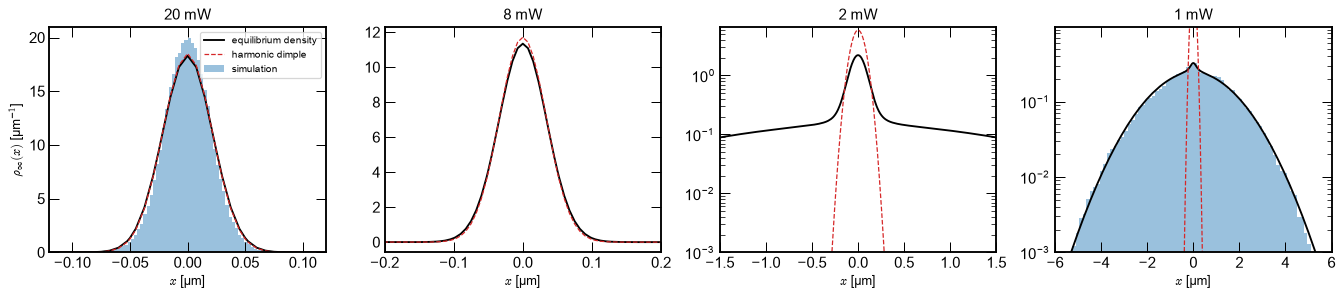

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, P in zip(axes, (20, 8, 2, 1)):
    D = density[P]
    ax.plot(D['x']/μm, D['ρ']*μm, 'k-', lw=1.5, label='equilibrium density')
    gauss = np.exp(-D['x']**2/(2*D['σ_harmonic']**2)) / np.sqrt(2*np.pi*D['σ_harmonic']**2)
    ax.plot(D['x']/μm, gauss*μm, 'C3--', lw=1, label='harmonic dimple')
    if P in runs:
        x = runs[P][1].x.values
        span = 5*D['σ_in'] if P == 20 else 6*μm
        ax.hist(x/μm, bins=np.linspace(-span, span, 81)/μm, density=True, color='C0', alpha=0.45, label='simulation')
    span = {20: 0.12, 8: 0.2, 2: 1.5, 1: 6}[P]
    ax.set_xlim(-span, span)
    if P in (2, 1):
        ax.set_yscale('log'); ax.set_ylim(1e-3, 3*np.max(D['ρ']*μm))
    ax.set_title(f'{P} mW'); ax.set_xlabel(r'$x$ [μm]')
axes[0].set_ylabel(r'$\rho_\infty(x)$ [μm$^{-1}$]')
axes[0].legend(fontsize=8, loc='upper right')
fig.tight_layout()

Compare with the paper's Fig. 4: a normal density at 20 mW, growing tails as the power drops, and at
1 mW a narrow peak in the dimple on top of the broad Paul-trap distribution (the log scale on the right
two panels shows the tails).

## Spectra (Fig. 5c)

1 mW: largest peak between 15 and 20 kHz at 18.37 kHz
1 mW: largest peak between 20 and 25 kHz at 20.69 kHz
micromotion sidebands expected at ω_d ∓ Ω_sec = 17.86, 22.14 kHz
stray field 10.0 V/m along x: offset 150 nm, micromotion amplitude at ω_d 22 nm


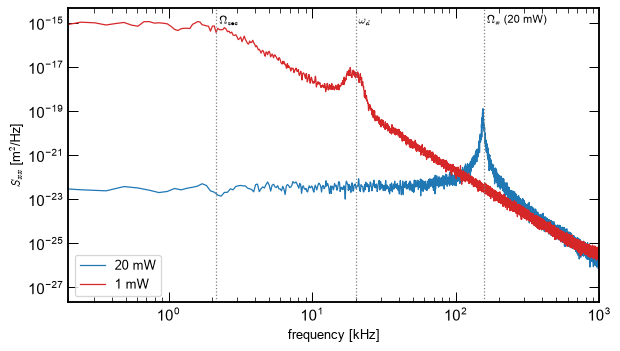

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for P, colour in ((20, 'C0'), (1, 'C3')):
    trap, sim = runs[P]
    f, S = welch(sim.x.values - sim.x.values.mean(), fs=1/sim.Δt, nperseg=2**15)
    ax.loglog(f/1e3, S, colour, lw=1, label=f'{P} mW')
Ω_sec = paul.secular_frequencies(particle, 'exact')[0]
for f0, text in ((Ω_d/Hz, r'$\omega_d$'), (Ω_sec/Hz, r'$\Omega_\mathrm{sec}$'), (runs[20][0].Ωx/Hz, r'$\Omega_x$ (20 mW)')):
    ax.axvline(f0/1e3, color='0.5', ls=':', lw=1)
    ax.text(f0/1e3*1.05, ax.get_ylim()[1]*0.2, text, fontsize=9)
ax.set_xlim(0.2, 1000); ax.set_xlabel('frequency [kHz]'); ax.set_ylabel(r'$S_{xx}$ [m$^2$/Hz]'); ax.legend()
fig.tight_layout()

f, S = welch(runs[1][1].x.values, fs=1/runs[1][1].Δt, nperseg=2**15)
for lo, hi in ((15e3, 20e3), (20e3, 25e3)):
    band = (f > lo) & (f < hi)
    print(f'1 mW: largest peak between {lo/1e3:.0f} and {hi/1e3:.0f} kHz at {f[band][np.argmax(S[band])]/1e3:.2f} kHz')
print(f'micromotion sidebands expected at ω_d ∓ Ω_sec = {(Ω_d - Ω_sec)/kHz:.2f}, {(Ω_d + Ω_sec)/kHz:.2f} kHz')

# a line at ω_d itself needs a static offset u from the rf null (excess micromotion), e.g. from a stray field
E_stray = 10.0    # V/m, illustrative
u = particle.q * E_stray / paul.secular_stiffness_diagonal(particle)[0]
print(f'stray field {E_stray} V/m along x: offset {u/nm:.0f} nm, micromotion amplitude at ω_d '
      f'{paul.excess_micromotion_amplitude((u, 0, 0), particle)[0]/nm:.0f} nm')

At 20 mW the spectrum is the thermal resonance of the optical dimple at 156 kHz. At 1 mW the particle
spends most of its time in the Paul trap: its secular motion (2.1 kHz, broadened by the 2.7 kHz gas
damping) and the micromotion sidebands around the drive dominate. In this simulation the particle is
centred on the rf null, so the micromotion appears as the sidebands at $\omega_d \mp \Omega_\mathrm{sec}$
= 17.9 and 22.1 kHz, which the gas damping broadens into one peak just below $\omega_d$ (maxima at 18.4
and 20.7 kHz), not as a line at $\omega_d$ itself. A line at the drive needs a static offset from the
null: the paper notes that stray fields are "never completely eliminated", and a stray field of 10 V/m
along the axis displaces the particle by 150 nm and drives a micromotion of 22 nm at $\omega_d$
(`UniformElectricField` adds such a field to a simulation).

## 5. Offsetting the Paul trap from the focus (Fig. 2)

`PaulTrap(centre=...)` displaces the trap. With the Paul trap centred at $c$ on the axis, the
deterministic force on the particle near the focus is $F_\mathrm{tw}(x) - k_x (x - c)$; the dimple holds
the particle as long as the largest optical restoring force exceeds $k_x c$.

In [8]:
k_x = paul.secular_stiffness_diagonal(particle)[0]
print(f'{"P [mW]":>7} {"max optical force [fN]":>23} {"critical offset [μm]":>21}')
for P in POWERS:
    trap = Trap(tweezer=tweezer(P*mW), bead=particle)
    print(f'{P:>7} {trap.max_Ftwx*1e15:23.2f} {trap.max_Ftwx / k_x / μm:21.1f}')

c = 5*μm
shifted = Trap(tweezer=tweezer(1*mW), bead=particle,
               extra_fields=[PaulTrap.ring(V, Ω_d, r0=1*mm, axis='x', κ_geom=0.5, centre=(c, 0, 0))])
print(f'\n1 mW, Paul trap centred at x = {c/μm:.0f} μm: equilibrium in the dimple at x = '
      f'{shifted.find_equilibrium()[0]/nm:.1f} nm (pseudopotential pull k_x c / k_tw = '
      f'{k_x*c/(shifted.kx - k_x)/nm:.1f} nm)')

 P [mW]  max optical force [fN]  critical offset [μm]
     20                 1144.14                 712.1
      8                  457.65                 284.8
      4                  228.83                 142.4
      2                  114.41                  71.2
      1                   57.21                  35.6

1 mW, Paul trap centred at x = 5 μm: equilibrium in the dimple at x = 18.0 nm (pseudopotential pull k_x c / k_tw = 18.0 nm)


Mechanically the dimple holds the particle for Paul-trap offsets of tens of μm even at 1 mW, because
the Paul trap is so soft. The paper observes the particle being lost at much smaller offsets: thermal
activation over the shallow optical barrier (4.8 $k_BT$ at 1 mW, section 3) and the stray fields
that it discusses limit the usable offset, not the deterministic force balance.

## Summary

| Quantity | levisim | Paper |
|---|---|---|
| $\epsilon = QV/d^2$ at the chosen $Q$, $V$, $d$ | 2.16 × 10⁻⁸ N/m, $q_x$ = 0.30, stable | range 4 × 10⁻⁹ to 3 × 10⁻⁵ N/m |
| Paul-trap secular frequencies (axial, radial) | 2.14, 1.06 kHz (exact); 2.10, 1.05 kHz (pseudopotential) | not stated ("typical" Paul traps, much lower than the optical ones) |
| nanodiamond, 10 mW, 532 nm, 0.8 NA | $\Omega_{x,y}/2\pi$ ≈ 520-530 kHz, $\Omega_z/2\pi$ ≈ 300 kHz (paraxial waist, upper estimate) | "hundreds of kHz" |
| power below which the density is non-Gaussian | kurtosis 0.02, 0.10, 1.7 at 20, 8, 4 mW | "below 8 mW ... deviate noticeably" |
| 1 mW | 90 % of the time outside the dimple (equilibrium); outside along $x$: simulation 39.8 %, equilibrium 41.3 %, 1601 crossings in 0.2 s | "leaves and re-enters the beam focus intermittently" |
| spectrum at 1 mW | secular motion at 2.1 kHz and a broad micromotion peak just below 20 kHz (sidebands at 17.9 and 22.1 kHz); a line at 20 kHz needs a stray field (10 V/m gives 22 nm) | "dynamics dominated by the Paul trap driving (peak at $\omega_d$ = 20 kHz)" |

Known limitations: the Paul-trap parameters and the particle radius are choices inside the paper's stated
ranges; the focus is a paraxial Gaussian beam; gravity and the scattering force are left out, as in the
paper. levisim's `Trap.Utw` and `Trap.U_depth` are the cycle-averaged dipole energy
$-(\mathrm{Re}\,\alpha/4)|E|^2$, the potential whose gradient is the force `Ftw` that the simulation
uses (before levisim 1.0 they were the peak energy, twice that).

In [9]:
print(f'runtime {time.time() - T_START:.0f} s')

runtime 8 s
